# Parte 2 - Exploracao dos dados (Slashdot)

Este notebook apresenta o dataset Slashdot e sua organização como uma rede de relações dirigidas entre usuários. A descrição das colunas, a leitura do arquivo e a visualização dos registros ajudam a compreender os dados utilizados na Parte 2 do projeto.

## 1. Sobre o dataset

O Slashdot é um site de notícias sobre tecnologia. O recurso Slashdot Zoo permite que um usuário marque outro como amigo ou inimigo. O dataset reúne essas relações.

Vamos utilizar o arquivo `soc-sign-Slashdot090221.txt.gz`, de 21 de fevereiro de 2009, disponível no [SNAP / Stanford](https://snap.stanford.edu/data/soc-sign-Slashdot090221.html).

Cada linha representa uma relação de um usuário para outro. Por isso, a rede é dirigida: uma marcação de A para B não significa que B também marcou A.

| Coluna | Significado |
| --- | --- |
| `origem` | Identificador do usuário que fez a marcação |
| `destino` | Identificador do usuário que recebeu a marcação |
| `sinal` | `1` para amigo e `-1` para inimigo |

## 2. Preparar a leitura

Selecione o Python do ambiente `.venv` do projeto. O bloco abaixo permite importar `ler_dataset`, a função que já criamos no `io.py`. Ele funciona com o notebook aberto pela raiz do projeto ou pela pasta `notebooks`.

In [44]:
from pathlib import Path
import sys

import pandas as pd

pasta_projeto = Path.cwd()
if pasta_projeto.name == "notebooks":
    pasta_projeto = pasta_projeto.parent

if str(pasta_projeto) not in sys.path:
    sys.path.insert(0, str(pasta_projeto))

from src.graphs.io import ler_dataset

## 3. Ler o arquivo

O arquivo deve estar em `data/dataset_parte2/`. A função `ler_dataset` abre o `.gz`, ignora os comentários e valida os dados antes de devolver a tabela. Não é necessário descompactar.

`dados.head()` mostra as cinco primeiras linhas, para vermos como as informações estão organizadas.

In [45]:
caminho_dataset = pasta_projeto / "data" / "dataset_parte2" / "soc-sign-Slashdot090221.txt.gz"
dados = ler_dataset(caminho_dataset)
dados.head()

,origem,destino,sinal
0,0,1,1
1,0,2,1
2,0,3,1
3,0,4,1
4,0,5,1


## 4. Pilar estrutural

As células abaixo levantam a estrutura da tabela: dimensões, tipos das colunas, valores nulos, linhas duplicadas, auto-laços e contagem dos sinais. Elas só produzem os números; a leitura de cada resultado é escrita pelo grupo logo abaixo.

### 4.1 Dimensões e tipos das colunas

In [46]:
# [IA] Claude – sintaxe pandas (shape, dtypes, memory_usage)
linhas, colunas = dados.shape
print(f"Linhas (relações): {linhas}")
print(f"Colunas: {colunas}")
print(f"Memória: {dados.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
dados.dtypes.to_frame("tipo")

Linhas (relações): 549202
Colunas: 3
Memória: 12.6 MB


,tipo
origem,int64
destino,int64
sinal,int64


**Interpretação:**

O dataset possui 549.202 registros e 3 colunas; cada linha representa uma relação dirigida entre dois usuários, ou seja, uma aresta do grafo.

O dataset possui 549.202 arcos, aproximadamente 9,84% acima da referência de 500 mil indicada no enunciado. Justificamos a sua escolha por representar uma rede real dirigida, com relações positivas e negativas, adequada à análise dos algoritmos exigidos.

Optamos por preservar a rede completa, pois remover arcos apenas para reduzir o tamanho poderia alterar graus, conectividade, caminhos e ciclos negativos. A viabilidade dos algoritmos mais custosos será avaliada pelos tempos e recursos medidos nos experimentos.

Embora armazenadas como `int64`, `origem` e `destino` são atributos nominais que identificam usuários, por isso não faz sentido calcular a média deles. `sinal` também é nominal e binário: +1 e −1 são códigos das categorias amigo e inimigo, não medidas de intensidade, e considerar amigo "melhor" é um julgamento que não define uma escala ordinal no dataset.

As três colunas não informam idade, localização ou motivos das relações, limitando a análise à estrutura da rede e aos sinais das conexões.

Os 12,6 MB ocupados pela tabela são modestos para um computador atual, mas construir o grafo e executar algoritmos pode exigir mais memória e processamento.

### 4.2 Quantidade de usuários (nós)

In [47]:
# [IA] Claude – sintaxe pandas (nunique, concat)
usuarios = pd.concat([dados["origem"], dados["destino"]]).nunique()
pd.Series(
    {
        "usuários que aparecem como origem": dados["origem"].nunique(),
        "usuários que aparecem como destino": dados["destino"].nunique(),
        "usuários no total (origem ou destino)": usuarios,
    },
    name="quantidade",
).to_frame()

,quantidade
usuários que aparecem como origem,44044
usuários que aparecem como destino,70284
usuários no total (origem ou destino),82140


**Interpretação:**

O grafo possui ordem |V| = 82.140, que corresponde aos usuários distintos na união de `origem` e `destino`. Somar as duas contagens (44.044 + 70.284) contaria duas vezes os 32.188 usuários presentes em ambos os grupos.

Existem 11.856 usuários que aparecem apenas como origem e têm, portanto, grau de entrada zero: fizeram marcações, mas não receberam nenhuma registrada neste dataset.

Outros 38.096 aparecem apenas como destino, com grau de saída zero: receberam marcações, mas não fizeram nenhuma registrada. Isso mostra que receber marcações abrange mais usuários do que fazê-las.

Uma BFS que respeite a direção dos arcos, iniciada em um usuário que só aparece como destino, visita somente ele. Para explorar outros nós, a fonte precisa ter grau de saída positivo; isso permite iniciar a exploração, mas não garante alcançar toda a rede.

A diferença de quatro usuários em relação ao cabeçalho do arquivo (82.144) pode decorrer de nós isolados, que não aparecem nas linhas de arestas, ou de uma inconsistência nos metadados. Essa contagem sozinha não confirma a causa.

### 4.3 Valores nulos

In [48]:
# [IA] Claude – sintaxe pandas (isna)
dados.isna().sum().to_frame("nulos")

,nulos
origem,0
destino,0
sinal,0


**Interpretação:**

Não foram encontrados valores nulos em `origem`, `destino` e `sinal`. Portanto, não é necessário remover registros nem imputar valores nessas colunas.

Entretanto, a ausência de um arco significa apenas que não há marcação registrada: pode haver desconhecimento, indiferença ou uma opinião não expressa, situações que o dataset não distingue.

Se o objetivo fosse conhecer essas opiniões não expressas, MNAR seria uma hipótese plausível, pois a decisão de registrar uma marcação pode depender da própria opinião. Isso, porém, não é comprovável apenas com os dados disponíveis.

Assim, manteremos os usuários e as relações observadas, sem criar arcos nem atribuir sinais às relações não registradas, pois isso inventaria informações e alteraria graus, caminhos e conectividade.

As conclusões ficam restritas à rede registrada: um caminho indica uma sequência de marcações, não necessariamente amizade, e a ausência de caminho não comprova ausência de vínculo social.

### 4.4 Linhas duplicadas

In [49]:
# [IA] Claude – sintaxe pandas (duplicated)
pd.Series(
    {
        "linhas idênticas (origem, destino e sinal)": dados.duplicated().sum(),
        "mesmo par (origem, destino) repetido": dados.duplicated(subset=["origem", "destino"]).sum(),
    },
    name="quantidade",
).to_frame()

,quantidade
"linhas idênticas (origem, destino e sinal)",0
"mesmo par (origem, destino) repetido",0


**Interpretação:**

Não foram encontradas linhas idênticas nem pares ordenados (`origem`, `destino`) repetidos. Portanto, não é necessário remover duplicatas.

Existe no máximo um arco em cada direção entre dois usuários, sem arcos paralelos. Para classificar o grafo como simples, também precisamos verificar a ausência de auto-laços, o que é feito na próxima seção.

Cada linha corresponde a um arco distinto; logo, o tamanho do grafo é |E| = 549.202, considerando todos os registros carregados.

Também não existem sinais conflitantes para um mesmo par ordenado, o que dispensa uma regra para escolher entre +1 e −1 ou para combinar registros.

A→B e B→A são arcos diferentes e podem coexistir: representam marcações nos dois sentidos e não são duplicatas.

A estrutura de dados permite representar um multigrafo, pois `adicionar_arco` acrescenta cada arco sem verificar repetições. Entretanto, como o dataset não possui pares ordenados repetidos e cada linha é carregada uma única vez, o grafo carregado não apresenta arcos paralelos.

### 4.5 Auto-laços (usuário que marca a si mesmo)

In [50]:
# [IA] Claude – sintaxe pandas (filtro booleano)
auto_lacos = dados[dados["origem"] == dados["destino"]]
print(f"Auto-laços: {len(auto_lacos)}")
auto_lacos.head()

Auto-laços: 0


,origem,destino,sinal


**Interpretação:**

Não foram encontrados auto-laços: nenhum usuário marcou a si mesmo como amigo ou inimigo nos registros carregados. Portanto, não há auto-laços a remover.

Juntando esse resultado à ausência de arcos paralelos verificada na seção 4.4, o grafo construído é dirigido e simples.

A densidade |E| / (|V| · (|V| − 1)) é adequada, pois cada usuário pode ter arcos para os outros |V| − 1 usuários, excluindo a si mesmo.

Se o sinal for usado como peso, um auto-laço com peso −1 seria um ciclo negativo de comprimento 1. Sem auto-laços, o menor ciclo possível tem comprimento 2, como A→B→A.

A ausência de automarcações é uma característica dos dados analisados, mas não permite concluir se o site as proíbe ou se elas foram removidas na preparação do dataset.

### 4.6 Contagem dos sinais

In [51]:
# [IA] Claude – sintaxe pandas (value_counts)
contagem = dados["sinal"].value_counts().to_frame("quantidade")
contagem["proporção (%)"] = (contagem["quantidade"] / len(dados) * 100).round(2)
contagem

,quantidade,proporção (%)
sinal,,
1,425072,77.4
-1,124130,22.6


**Interpretação:**

Foram encontrados apenas os sinais +1 e −1, confirmando as duas categorias previstas: 425.072 marcações de amigo (77,4%) e 124.130 de inimigo (22,6%).

As classes são desbalanceadas, com aproximadamente 3,42 marcações de amigo para cada marcação de inimigo. Os pesos negativos vêm do dataset original, o que atende ao requisito de não serem inventados pelo grupo.

Essa predominância descreve as marcações registradas, mas não explica suas motivações nem revela se os sinais negativos estão concentrados em poucos usuários. Para isso, é preciso analisar os graus de entrada e de saída separados por sinal.

O Dijkstra não deve ser aplicado diretamente com esses pesos negativos. A transformação para pesos não negativos e o seu significado serão justificados na seção dos algoritmos, deixando claro que ela pode mudar os caminhos mínimos.

A presença de arcos negativos não garante ciclos negativos: é necessário um ciclo cuja soma dos pesos seja negativa. No caso A→B→A, ambos os arcos precisam ter peso −1.

## 5. Pilar distribucional

Esta seção monta a tabela `graus`, com uma linha por usuário, separando as marcações feitas (saída) e recebidas (entrada) por sinal. Ela é a base para estudar as distribuições de grau. As células só produzem os números; a leitura é escrita pelo grupo.

### 5.1 Tabela de graus por usuário

| Coluna | Significado |
| --- | --- |
| `saida_pos` / `saida_neg` | marcações de amigo / inimigo que o usuário **fez** |
| `entrada_pos` / `entrada_neg` | marcações de amigo / inimigo que o usuário **recebeu** |
| `grau_saida` | `saida_pos + saida_neg` |
| `grau_entrada` | `entrada_pos + entrada_neg` |

In [52]:
# [IA] Claude – sintaxe pandas (groupby, unstack, reindex)
# conta as linhas por (usuario, sinal) e vira os sinais em colunas
saida = dados.groupby(["origem", "sinal"]).size().unstack(fill_value=0)
entrada = dados.groupby(["destino", "sinal"]).size().unstack(fill_value=0)

# todos os usuarios (origem ou destino); quem nao aparece de um lado fica com 0
todos = pd.Index(pd.concat([dados["origem"], dados["destino"]]).unique(), name="usuario").sort_values()
saida = saida.reindex(todos, fill_value=0)
entrada = entrada.reindex(todos, fill_value=0)

graus = pd.DataFrame(
    {
        "saida_pos": saida[1],
        "saida_neg": saida[-1],
        "entrada_pos": entrada[1],
        "entrada_neg": entrada[-1],
    }
)
graus["grau_saida"] = graus["saida_pos"] + graus["saida_neg"]
graus["grau_entrada"] = graus["entrada_pos"] + graus["entrada_neg"]
graus.head(10)

,saida_pos,saida_neg,entrada_pos,entrada_neg,grau_saida,grau_entrada
usuario,,,,,,
0,24,5,199,29,29,228
1,71,24,95,21,95,116
2,0,0,20,0,0,20
3,11,0,48,5,11,53
4,1,0,109,15,1,124
5,74,5,33,1,79,34
6,17,0,8,0,17,8
7,21,8,47,58,29,105
8,102,83,481,118,185,599


### 5.2 Conferência da tabela com as seções anteriores

In [53]:
# [IA] Claude – sintaxe pandas (sum, filtro booleano)
pd.Series(
    {
        "usuários na tabela (4.2: 82140)": len(graus),
        "soma dos graus de saída (|E| = 549202)": graus["grau_saida"].sum(),
        "soma dos graus de entrada (|E| = 549202)": graus["grau_entrada"].sum(),
        "marcações negativas feitas (4.6: 124130)": graus["saida_neg"].sum(),
        "marcações negativas recebidas (4.6: 124130)": graus["entrada_neg"].sum(),
        "usuários com grau de entrada 0 (4.2: 11856)": (graus["grau_entrada"] == 0).sum(),
        "usuários com grau de saída 0 (4.2: 38096)": (graus["grau_saida"] == 0).sum(),
    },
    name="valor",
).to_frame()

,valor
usuários na tabela (4.2: 82140),82140
soma dos graus de saída (|E| = 549202),549202
soma dos graus de entrada (|E| = 549202),549202
marcações negativas feitas (4.6: 124130),124130
marcações negativas recebidas (4.6: 124130),124130
usuários com grau de entrada 0 (4.2: 11856),11856
usuários com grau de saída 0 (4.2: 38096),38096


**Interpretação:**

Os sete valores coincidem com os resultados anteriores, o que reforça a consistência da tabela `graus`, embora isso não comprove individualmente cada linha.

As somas dos graus de saída e de entrada são iguais a 549.202, pois cada arco contribui uma vez para a saída de sua origem e uma vez para a entrada de seu destino. Pelo mesmo motivo, as marcações negativas feitas e recebidas totalizam, cada uma, 124.130: são os mesmos arcos contados pelas duas extremidades.

Também foram identificados 11.856 usuários com grau de entrada zero e 38.096 com grau de saída zero, agora pela contagem direta dos graus. A concordância com o cálculo por conjuntos da seção 4.2 funciona como uma verificação complementar.

### 5.3 Resumo estatístico dos graus

In [54]:
# [IA] Claude – sintaxe pandas (describe)
graus.describe().round(2)

,saida_pos,saida_neg,entrada_pos,entrada_neg,grau_saida,grau_entrada
count,82140.00,82140.00,82140.00,82140.00,82140.00,82140.00
mean,5.17,1.51,5.17,1.51,6.69,6.69
std,18.58,9.94,27.33,7.59,23.57,31.39
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.00,0.00,1.00,0.00,0.00,1.00
50%,1.00,0.00,1.00,0.00,1.00,1.00
75%,3.00,0.00,3.00,1.00,3.00,4.00
max,428.00,400.00,2512.00,498.00,428.00,2543.00


**Interpretação:**

As médias dos graus de entrada e de saída são iguais porque ambas correspondem a |E|/|V| = 549.202/82.140 ≈ 6,69.

A média do grau de saída supera a mediana, igual a 1, em aproximadamente 5,69. Isso indica assimetria à direita, com valores elevados puxando a média.

Enquanto pelo menos 75% dos usuários recebem no máximo 4 marcações, um usuário recebe 2.543, o que caracteriza um extremo de grande visibilidade, sem necessariamente indicar prestígio. O maior máximo e o maior desvio-padrão da entrada sugerem maior desigualdade no recebimento de marcações do que na realização delas, complementando a seção 4.2.

Quanto aos sinais negativos, pelo menos 75% dos usuários não fizeram nenhuma marcação de inimigo; pelo menos metade não recebeu nenhuma e 75% receberam no máximo uma, embora os máximos cheguem a 400 feitas e 498 recebidas. Isso revela concentração parcial, mas, para quantificá-la, seria necessário medir a participação dos usuários com maiores graus negativos no total.

A mediana e os quartis descrevem melhor o usuário típico. Nos gráficos, os extremos exigem uma apresentação que evidencie os graus baixos e a cauda, como escala logarítmica com tratamento explícito dos zeros.

### 5.4 Distribuição dos graus de entrada e de saída

Visualização exploratória 1. Tipo de gráfico, colunas, cores e tratamento dos zeros foram definidos pelo grupo: dispersão de grau × número de usuários, eixos em escala logarítmica com os mesmos limites nos dois painéis, e os usuários com grau zero anotados fora da escala. A figura também é salva em `out/parte2/distribuicao_graus.png`.

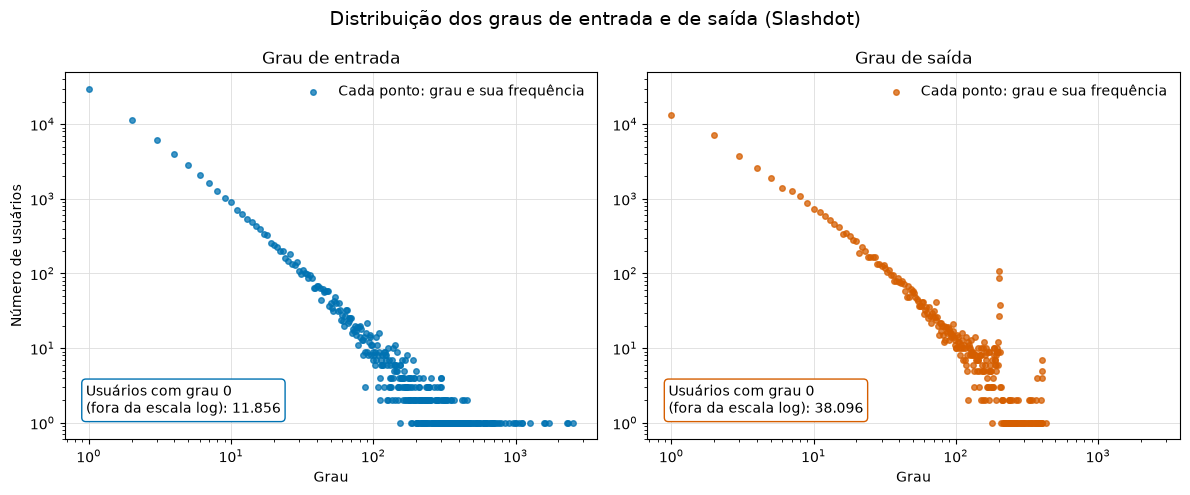

In [55]:
# [IA] Claude – sintaxe matplotlib (subplots, scatter, escala log, text, savefig)
import matplotlib.pyplot as plt

paineis = [
    ("grau_entrada", "Grau de entrada", "#0072B2"),
    ("grau_saida", "Grau de saída", "#D55E00"),
]

# sharex/sharey: os dois paineis usam os mesmos limites nos eixos
fig, eixos = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True, facecolor="white")

for ax, (coluna, nome, cor) in zip(eixos, paineis):
    # quantos usuarios tem cada valor de grau (calculado com todos os usuarios)
    frequencia = graus[coluna].value_counts().sort_index()
    zeros = frequencia.get(0, 0)
    positivos = frequencia[frequencia.index > 0]  # zero nao existe na escala log

    ax.scatter(positivos.index, positivos.values, s=16, color=cor, alpha=0.75,
               label="Cada ponto: grau e sua frequência")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(nome)
    ax.set_xlabel("Grau")
    ax.set_facecolor("white")
    ax.grid(True, which="major", color="#dddddd", linewidth=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(labelleft=True)
    ax.legend(loc="upper right", frameon=False)

    texto_zeros = f"{zeros:,}".replace(",", ".")
    ax.text(0.04, 0.06, f"Usuários com grau 0\n(fora da escala log): {texto_zeros}",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=10,
            bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": cor})

eixos[0].set_ylabel("Número de usuários")
fig.suptitle("Distribuição dos graus de entrada e de saída (Slashdot)", fontsize=14)
fig.tight_layout()

pasta_figuras = pasta_projeto / "out" / "parte2"
pasta_figuras.mkdir(parents=True, exist_ok=True)
fig.savefig(pasta_figuras / "distribuicao_graus.png", dpi=150, facecolor="white", bbox_inches="tight")
plt.show()

**Nota analítica:**

**O que está sendo mostrado.** O gráfico mostra quantos usuários possuem cada grau de entrada (azul) e de saída (laranja). Cada ponto representa um valor de grau e a sua frequência.

**Insight.** Nos dois painéis predominam graus baixos, enquanto graus elevados aparecem em poucos usuários. A distribuição de entrada se estende até 2.543, contra 428 na saída, o que mostra extremos maiores no recebimento de marcações. As anotações também evidenciam mais usuários sem marcações feitas (38.096) do que sem marcações recebidas (11.856).

**Por que este tipo de visualização.** A dispersão foi escolhida para mostrar as frequências de cada grau sem agrupá-los em intervalos, e as escalas logarítmicas permitem observar simultaneamente valores frequentes e extremos. Os limites iguais facilitam a comparação entre os painéis, e os zeros são informados separadamente por não poderem ser representados na escala logarítmica.

## 6. Amostragem para os experimentos

A exploração utiliza a rede completa; os experimentos usam recortes com 10%, 50% e 100% dos usuários. Os identificadores são ordenados e embaralhados com a semente 42, e cada recorte usa o início da mesma lista, mantendo os menores contidos nos maiores. O subgrafo induzido preserva os nós selecionados e os arcos entre eles, com sua direção e sinal.

Os percentuais se referem aos nós, não aos arcos; 100% corresponde à rede original. Os recortes podem ficar desconectados, e seus graus, caminhos e ciclos não devem ser generalizados para a rede completa. A estratégia deve ser conferida com a proposta aprovada e com a professora.

In [14]:
# [IA] ChatGPT - apoio na implementacao dos recortes reproduziveis
import random

from src.graphs.io import montar_grafo_dataset

semente = 42
percentuais = [10, 50, 100]
grafo_completo = montar_grafo_dataset(dados)

usuarios_sorteados = sorted(grafo_completo.nos())
random.Random(semente).shuffle(usuarios_sorteados)

recortes = {}
resumo_recortes = []

for percentual in percentuais:
    quantidade = grafo_completo.ordem() * percentual // 100
    recorte = grafo_completo.subgrafo_induzido(usuarios_sorteados[:quantidade])

    recortes[percentual] = recorte
    resumo_recortes.append({
        "usuarios (%)": percentual,
        "nos": recorte.ordem(),
        "arcos": recorte.tamanho(),
        "arcos (%)": round(recorte.tamanho() / grafo_completo.tamanho() * 100, 2),
    })

pd.DataFrame(resumo_recortes).set_index("usuarios (%)")

,nos,arcos,arcos (%)
usuarios (%),,,
10,8214,5434,0.99
50,41070,134558,24.50
100,82140,549202,100.00
